<a href="https://colab.research.google.com/github/Yan-cabore/Atividades_Visao_Computacional_iRede/blob/main/atividade04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 4: **Segmentação, Operações Morfológicas e Extração de Características**

___

## Aluno: Carlos Yan Matos Ferreira

### Nota:
Adicionei uma nova classe dentro do meu dataset, a `Classe C`. Esta classe será responsável por armazenar imagens extras, já que, como visto na atividade atual, foi preciso usar uma imagem que atendesse a requisitos mais específicos.

## Dataset:
*   **Classe_C/objetos.jpeg:** A imagem contém 7 objetos distintos entre si: um pequeno brinquedo Lego, uma moeda de 1 real, uma de 50 centavos, uma de 5 centavos, um coringa de um baralho, um Arduino e uma etiqueta feita por impressão 3D.

*   **Justificativa:** Como dito anteriormente, decidi criar uma classe extra para capturar novas imagens que atendam a qualquer requerimento extra, como o da atividade atual. Decidi fazer com que a imagem selecionada fosse bem diversificada, possibilitando uma análise mais completa dos resultados da aplicação do processo de segmentação e das operações de morfologia matemática.  

---

## Registro da Imagem

## Ferramentas Próprias

Nesta atividade, eu reutilizei e estendi a classe unificada `VisionUtils` que desenvolvi em módulos anteriores. Esta classe abstrai tarefas repetitivas de renderização com `matplotlib`, facilitando a plotagem padronizada dos passos do meu pipeline de Visão Computacional.

### Métodos Disponíveis:
1. `ler_imagem`: Carregamento robusto via OpenCV com conversão de espaço de cores.
2. `criar_figure`: Inicialização estruturada de subplots.
3. `preencher_figure`: Vinculação de imagens e canais de cores aos subplots criados.
4. `nomear_axes`: Adição facilitada de títulos aos eixos.
5. `remover_axis`: Ocultação de marcações de coordenadas para visualização limpa.
6. `converter_tons_cinza`: Conversão otimizada de RGB para escala de cinza.

## Dependências e Imagem

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import logging
from skimage.measure import label, regionprops
from skimage.filters import threshold_otsu
from google.colab import files


# Selecione a imagem (Classe C/objetos.jpeg)
upload = files.upload()

Saving objetos.jpeg to objetos (1).jpeg


## VisionUtils

In [ ]:
class VisionUtils():

  def __init__(self):
    return

  def ler_imagens(self, img_list: list, type=None): # método para ler as imagens

    for i in range(len(img_list)): # decidi passar as imagens como uma lista de nomes para iterar sobre.
      img_list[i] = cv.imread(img_list[i], cv.IMREAD_COLOR_RGB) # lendo imagem por imagem
      # o cv.IMREAD já lê como RGB

    return img_list

  def criar_figure(self, fig_name, axes_x, axes_y, fig_size): # método para criar figure (retorna axes 1D ou 2D dependendo de axes_x, axes_y)
    fig, ax = plt.subplots(axes_x, axes_y, figsize=fig_size, squeeze=False)
    fig.suptitle(fig_name)
    fig.tight_layout() # método para deixar a figure criada mais normalizada

    return fig, ax
                                                  # cmap ficou como None porque só preciso dele em gray
  def preencher_figure(self, axe, img_list: list, cmap=None): # método para preencher axes 1D ou 2D com as imagens
    for i, linha in enumerate(axe):
      for j, ax in enumerate(linha):
        ax.imshow(img_list[i][j], cmap=cmap)

  def nomear_axes(self, axe, names: list): # método para nomear cada um dos axes (1D ou 2D)
    for i, linha in enumerate(axe): # itero sobre cada linha da grade de axes
      for j, ax in enumerate(linha): # itero sobre cada axe dentro da linha
        ax.set_title(names[i][j]) # nomear
    return

  def remover_axis(self, axe): # método para remover os axis da figure, seguindo o padrão ensinado pelo professor
    for a in axe:
      a.axis('off')
    return

  def adicionar_imagem(self, axe, img): # método para adicionar imagem a axes vazios
    for ax in axe:
      if not ax.has_data(): # a ideia é percorrer cada um usando o método has_data, que informa se o axe está preenchido ou não
        ax.imshow(img) # preenche o axe quando vazio
        break          # se não houvesse break, o laço preencheria qualquer axe vazio
    return               # no momento em que ele preenche um espaço, o laço quebra
                         # assim, adiciono só uma imagem em um axe por vez

## 1. Visualização da Imagem Original

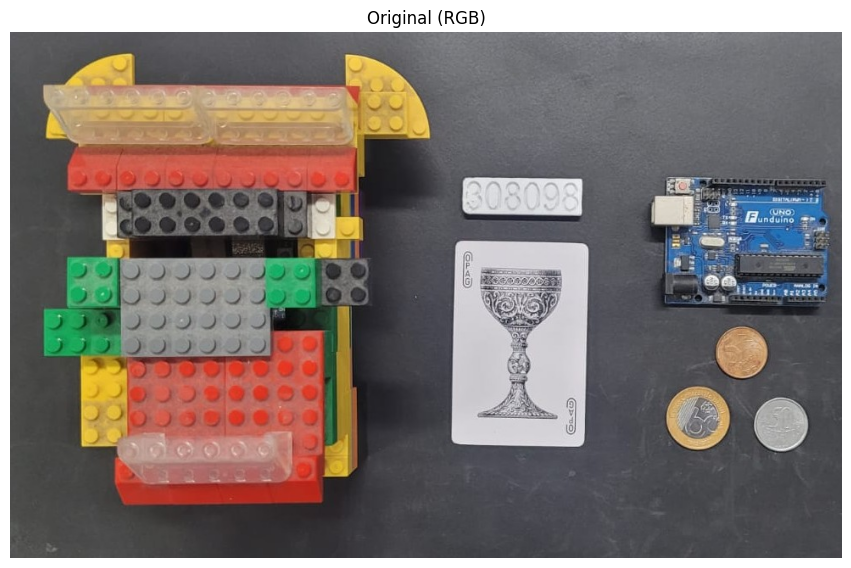

In [ ]:
vision = VisionUtils()

# Carrega a imagem uma única vez de forma padronizada
imagens_lidas = vision.ler_imagens(["objetos.jpeg"])
objetos = imagens_lidas[0]

# Exibição da imagem original usando as ferramentas da classe VisionUtils
imgs = [[objetos]]
names = [["Original (RGB)"]]
fig, ax = vision.criar_figure("", 1, 1, (12, 6))
vision.preencher_figure(ax, imgs)
vision.nomear_axes(ax, names)
vision.remover_axis(ax.flatten())
plt.show()

## Objetos da imagem:

* **Carta**: Um coringa retirado do meu baralho. Selecionei-o por apresentar a arte gráfica mais detalhada e de maior tamanho entre todas as cartas do baralho.

* **Moedas**: Uma moeda de 1 real (edição de 60 anos do Banco do Brasil), uma de 50 centavos de 1994 e outra de 5 centavos. Selecionei as moedas por serem objetos clássicos para testes de segmentação.

* **Etiqueta 3D**: A pequena placa branca é uma impressão 3D, feita para servir como etiqueta de um extintor de incêndio.

* **Brinquedo**: O brinquedo foi construído com peças de Lego, apresentando uma textura única, além de ter um formato bem incomum, o que chamou bastante a minha atenção.

* **Arduino**: A pequena placa foi selecionada por apresentar um alto nível de detalhamento. O objetivo é analisar como ela será segmentada e interpretada ao longo da atividade.  

---

## 2. Segmentação Global (Otsu)

Limiar encontrado: 126.00


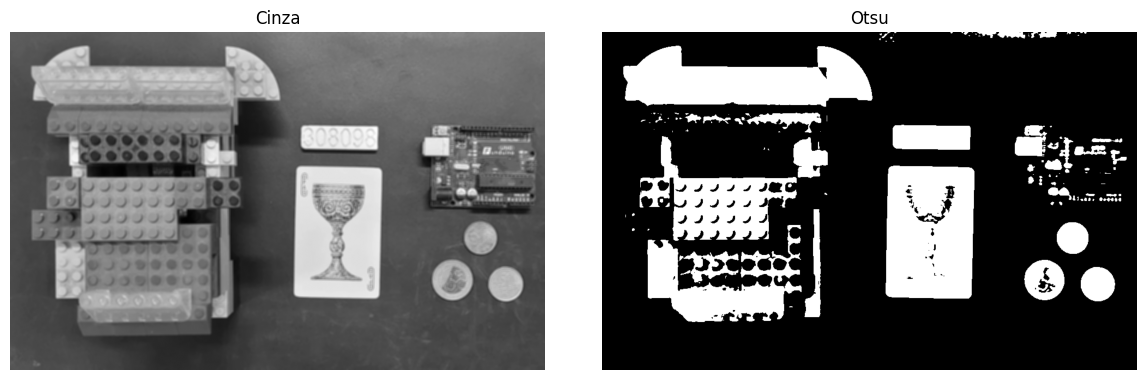

In [ ]:
from skimage.filters import threshold_otsu

vision = VisionUtils()

# Conversão da imagem para escala-cinza
gray = cv.cvtColor(objetos, cv.COLOR_RGB2GRAY)

# Uso do filtro gaussiano para atenuar o gradiente de luz no topo da imagem
gray = cv.GaussianBlur(gray, (5, 5), 3)

# Otsu: calcula o limiar global e devolve ele
limiar_otsu = threshold_otsu(gray)
# Gera a máscara binária
otsu = gray > limiar_otsu
print(f"Limiar encontrado: {limiar_otsu:.2f}")

# Exibição da imagem original e imagem segmentada
imgs = [[gray, otsu]]
names = [["Cinza", "Otsu"]]
fig, ax = vision.criar_figure("", 1, 2, (12, 6))
vision.preencher_figure(ax, imgs, cmap='gray')
vision.nomear_axes(ax, names)
vision.remover_axis(ax.flatten())
plt.show()

### Observações:

*   **Escolha do Método:** Escolhi o método de Otsu por ser o que melhor atende ao objetivo do exercício, que é separar objeto e fundo por regiões preenchidas. O Otsu, por usar um limiar global, preencheu de forma consistente as regiões claras e homogêneas, como a carta, as moedas e a placa numerada, entregando máscaras de objetos mais preenchidas em comparação a outros métodos que tentei usar anteriormente (como o de Sauvola).

*   **Dificuldades:** Na imagem, os tons das peças do brinquedo (peças cinza-escuro), da placa Arduino e de uma pequena porção da arte na carta se sobrepõem aos do fundo. Nenhum limiar único separa bem esses elementos, então parte deles foi classificada como fundo, deixando buracos e regiões fragmentadas. Também apareceram pontos de ruído no canto superior direito por conta de um leve gradiente de iluminação causado pela lâmpada logo acima de onde tirei a foto, o que fez o fundo ali cruzar o limiar global. Tentei usar o filtro da mediana para atenuar o ruído, o que funcionou nas primeiras tentativas, mas, infelizmente, o filtro atrapalhou no momento de segmentar as bordas. Isso me levou a usar o filtro Gaussiano, permitindo uma maior preservação dos objetos na segmentação.

*   **Resultado:** O Otsu separou bem a carta, as moedas e a placa numerada do fundo, gerando objetos preenchidos e sem contornos duplicados. O brinquedo foi segmentado apenas parcialmente (a parte clara foi preenchida, mas as peças escuras foram associadas ao fundo) e o Arduino ficou incompleto. Não houve união relevante entre as fronteiras dos objetos, já que eles estão bem espaçados; os principais erros vieram da sobreposição de tons, e não de fatores de iluminação, exceto pelo ruído isolado no canto superior direito. Como evidência, basta analisar como os objetos mais bem segmentados na imagem são aqueles de tonalidade mais clara (intensidade mais alta). Isso enfatiza a importância de ter um fundo que já se destaque dos objetos antes mesmo de a segmentação ser realizada.

## 3. Operações Morfológicas

## Fechamento & Refinamento

* Fiz uso dos métodos da biblioteca `skimage` para realizar um refinamento morfológico sequencial completo, preenchendo os buracos na máscara gerada pelo Otsu, eliminando ruídos indesejados e suavizando as bordas para a etapa final de rotulagem.

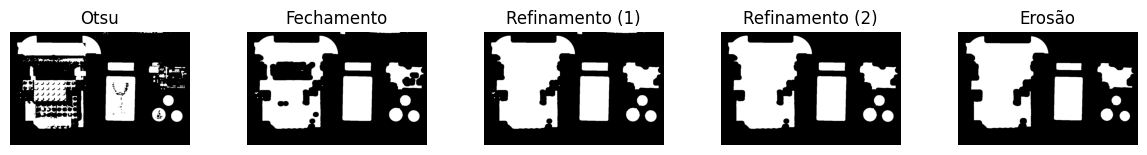

In [ ]:
from skimage import morphology

vision = VisionUtils()

# Define os elementos estruturantes (footprints) em formato de elipse
# Usei dois para usar um em operações menos agressivas
footprint_1 = morphology.ellipse(3, 3)
footprint_2 = morphology.ellipse(15, 13)

# 1. Fechamento para unir componentes e fechar falhas na máscara
fechamento = morphology.closing(otsu, footprint=footprint_2)

# 2. Remove buracos escuros internos nos objetos
refinada_1 = morphology.remove_small_holes(fechamento, area_threshold=30000)

# 3. Eliminação de pequenos ruídos gerados na máscara
refinada_2 = morphology.remove_small_objects(refinada_1, min_size=2000)

# 4. Erosão para suavizar as bordas
erosao = morphology.erosion(refinada_2, footprint=footprint_1)

imgs = [[otsu, fechamento, refinada_1, refinada_2, erosao]]
nomes = [["Otsu", "Fechamento", "Refinamento (1)", "Refinamento (2)", "Erosão"]]

fig, ax = vision.criar_figure("", 1, 5, (12, 6))
vision.preencher_figure(ax, imgs, cmap='gray')
vision.nomear_axes(ax, nomes)
vision.remover_axis(ax.flatten())
plt.show()

### Análise das Operações Morfológicas

Após a segmentação com Otsu, eu apliquei um pipeline de refinamento morfológico combinando operações básicas e filtros estruturados baseados em área.

**Imagens após cada operação**

*   **Fechamento:** A máscara bruta do Otsu perdeu as ranhuras e texturas excessivas, sendo devidamente preenchida. O brinquedo de Lego perdeu as divisões internas de suas peças, a arte gráfica interna da carta foi unificada, a moeda de edição especial foi preenchida internamente e o Arduino recuperou parte expressiva da área de seu circuito. A etiqueta permaneceu intacta e bem definida, já que sempre apresentou ótimo contraste com o fundo. Contudo, alguns pequenos ruídos de iluminação no topo do fundo se expandiram devido à etapa de dilatação intrínseca ao fechamento.

*   **Refinamento (1) (`remove_small_holes`):** Esta etapa preencheu os buracos escuros restantes de forma cirúrgica. O Lego e o Arduino foram os mais beneficiados, pois tiveram preenchidas as cavidades que o fechamento sozinho não conseguiu cobrir por serem maiores que o elemento estruturante. O método atua recebendo uma área limite em pixels, na qual qualquer cavidade menor ou igual ao valor definido (30.000 px) é solidificada. Escolhi o valor de 30.000 por tentativa e erro. Comecei com valores pequenos e fui aumentando até que os buracos fossem completamente preenchidos.

*   **Refinamento (2) (`remove_small_objects`):** Com este filtro de área, consegui remover com precisão os pequenos fragmentos isolados e ruídos que haviam se expandido na etapa de fechamento (principalmente no topo da imagem e próximo à lateral esquerda do Lego). Eliminei todas as regiões desconexas menores que 2.000 px. Encontrei esse valor da mesma forma que o anterior, por meio de tentativa e erro.

*   **Erosão:** A erosão final atuou como um ajuste estético essencial para atenuar o inchaço inevitável causado pelo fechamento. Ela reduziu de forma controlada as bordas dos objetos, aproximando as formas e as áreas das regiões binárias aos limites reais dos objetos originais.

* **Nota**: Por questões de validação, deixei logo após esta célula uma demonstração de como as máscaras se comportaram com diferentes valores nos métodos para remover buracos e pequenos ruídos.

**Como a estrutura das imagens mudou**

*   **Otsu para Fechamento:** Os objetos que antes estavam fragmentados e cheios de furos texturizados (como o Lego e o Arduino) ganharam massa e conectividade. O fechamento conseguiu selar e preencher a maior parte dessas falhas estruturais, porém expandiu pequenos ruídos pontuais que estavam no fundo da imagem e criou um leve inchaço nas bordas de todos os objetos.
*   **Fechamento para Refinamento (1):** A estrutura dos objetos maiores tornou-se completamente sólida. O preenchimento de buracos com o `remove_small_holes` eliminou vazios massivos que o fechamento sozinho não conseguiu cobrir (especialmente no centro do brinquedo de Lego e nas trilhas do Arduino), sem alterar as bordas externas dos objetos.
*   **Refinamento (1) para Refinamento (2):** A estrutura geral dos objetos principais manteve-se intacta, mas limpei o fundo por completo. Toda aquela poeira de ruído fino e os pontos espalhados no topo da imagem sumiram, deixando as formas dos objetos isoladas e bem delineadas.
*   **Refinamento (2) para Erosão:** Os objetos sofreram uma leve redução em sua espessura, suavizando contornos serrilhados gerados pelas etapas anteriores. Isso devolveu um aspecto visual mais natural às bordas da etiqueta, da carta e das moedas, reduzindo o acúmulo excessivo de área branca.

**Comparação entre as etapas**

*   **Máscara Original (Otsu) vs. Pós-Processamento:** A máscara bruta do Otsu era muito ruidosa e incompleta devido à sobreposição de tons. O pipeline de operações morfológicas que estruturei transformou um resultado segmentado cheio de falhas em regiões sólidas, contínuas e prontas para uma rotulagem confiável.
*   **Fechamento vs. Refinamento por Métodos de Área (`remove_small_holes` e `remove_small_objects`):** Enquanto o fechamento morfológico convencional depende estritamente do tamanho do elemento estruturante e pode causar deformações se usado com raio muito grande, usei os métodos baseados em área para limpar o fundo e preencher buracos profundos de maneira cirúrgica, atuando apenas na conectividade interna sem afetar as fronteiras dos objetos.
*   **Refinamento Final vs. Erosão:** O refinamento por área garantiu que a imagem ficasse livre de buracos e ruídos indesejados, enquanto a erosão final me serviu como um ajuste estético essencial, reduzindo o ganho de área inevitável que as etapas de dilatação do fechamento haviam causado nos contornos originais.

**Qual problema tentei resolver com cada operação**

*   **Fechamento:** Unificar fragmentos de objetos e preencher pequenas lacunas causadas pela limiarização de Otsu.
*   **`remove_small_holes`:** Eliminar cavidades pretas de tamanho intermediário no interior dos objetos segmentados que persistiram ao fechamento.
*   **`remove_small_objects`:** Excluir ruídos brancos residuais e espúrios que restaram espalhados no fundo.
*   **Erosão:** Suavizar as bordas e compensar o inchaço de contorno acumulado nas etapas anteriores.

**Conclusão:** O fechamento morfológico associado aos filtros por área e ao ajuste final de erosão me permitiu converter um resultado bruto e segmentado de forma parcial em máscaras ideais e homogêneas, viabilizando o sucesso da minha etapa de rotulagem subsequente.

---

### Validação de Parâmetros

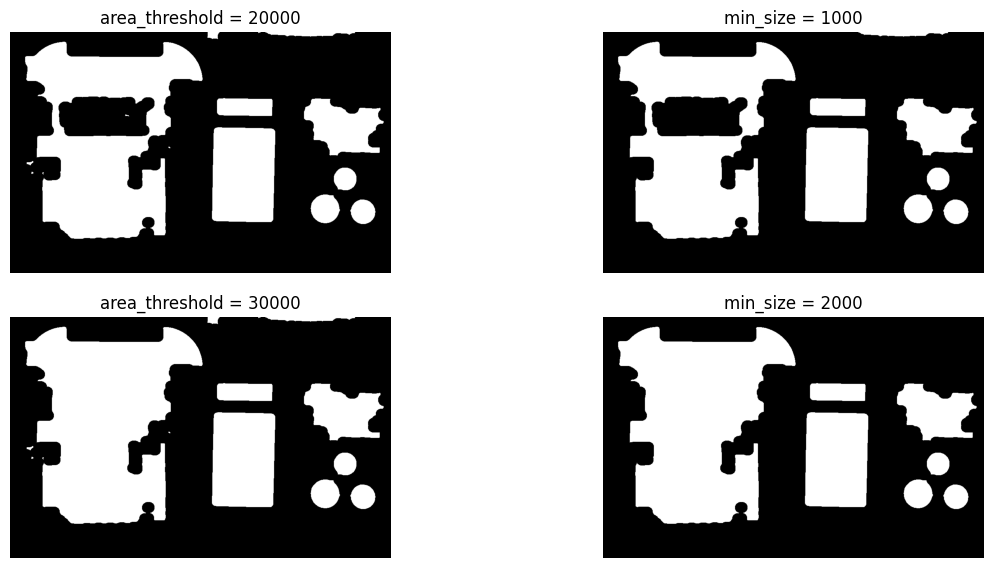

In [ ]:
validacao_holes = morphology.remove_small_holes(fechamento, area_threshold=20000)
validacao_noise = morphology.remove_small_objects(validacao_holes, min_size=1000)

imgs = [[validacao_holes, validacao_noise],
        [refinada_1, refinada_2]]
nomes_2 = [["area_threshold = 20000", "min_size = 1000"],
           ["area_threshold = 30000", "min_size = 2000"]]

fig, ax = vision.criar_figure("", 2, 2, (12, 6))
vision.preencher_figure(ax, imgs, cmap='gray')
vision.nomear_axes(ax, nomes_2)
vision.remover_axis(ax.flatten())

plt.show()

* `area_threshold`: Para encontrar o valor ideal que preencheria o buraco, fui acrescentando de 10.000 em 10.000 ao valor da variável, até encontrar um limite que cobrisse tudo de forma satisfatória. O valor de 20.000 foi o último antes de eu conseguir preencher as falhas da maneira como queria. O valor de 30.000 preencheu com segurança todos os buracos internos do Lego e do Arduino.

* `min_size`: Utilizei um raciocínio similar ao da etapa anterior, começando com o valor de 1.000. Para a remoção de pequenos ruídos dispersos, valores abaixo de 1.000 já eram suficientes. Contudo, para apagar o grande bloco de ruído no topo da imagem, foi necessário elevar o parâmetro para 2.000, obtendo assim um resultado completamente limpo e satisfatório.

## 4. Identificação de Objetos

In [ ]:
from skimage.measure import label

# Rotula a máscara mais adequada (erosao)
labels, num = label(erosao, return_num=True, connectivity=2)

fig, ax = vision.criar_figure("", 1, 1, (12, 6))

# Sobreposição das imagens para validação visual
nomes = [["Sobreposição"]]

plt.imshow(gray, cmap='gray')
plt.imshow(labels, cmap='nipy_spectral', alpha=0.5)
vision.nomear_axes(ax, nomes)
vision.remover_axis(ax.flatten())

print(f"A imagem possui {num} objetos no total")

### Identificação de Objetos com o método `label` do skimage

Eu apliquei a rotulagem de objetos utilizando o método `label` da biblioteca `skimage` (configurado com conectividade 8/vizinhos de 8 pontos) diretamente sobre a minha máscara refinada (`erosao`), obtida após o fechamento e o pós-processamento de áreas. A figura acima ilustra os meus resultados de forma visual, onde cada objeto mapeado e identificado recebe uma cor própria baseada no seu rótulo numérico.

**Número total de objetos que encontrei:** 7 (Retornado pelo parâmetro `return_num` da função `label`)

| Cor | Objeto identificado |
|---|---|
| Azul escuro | Brinquedo de Lego |
| Azul claro | Etiqueta numerada ("308098") |
| Verde claro | Carta |
| Verde escuro | Arduino |
| Amarelo | Moeda (superior) |
| Vermelho | Moeda (inferior esquerda) |
| Cinza | Moeda (inferior direita) |

**Todos os objetos foram corretamente identificados?**

Sim, no que diz respeito à contagem. Os 7 objetos esperados (Lego, etiqueta, carta, Arduino e as três moedas) aparecem como regiões separadas, cada uma com um rótulo único. As moedas não se fundiram entre si nem com os demais objetos, e a carta e a etiqueta continuaram independentes.

A **qualidade** da identificação, porém, varia:

*   **Carta, etiqueta e moedas:** Apresentaram regiões sólidas e com formato muito próximo ao do objeto real, embora uma porção pequena dos contornos externos tenha ficado ligeiramente reduzida após a erosão que executei.

*   **Lego:** Foi rotulado como um único objeto, mas a região resultante possui contorno irregular e alguns pequenos buracos internos que resistiram aos filtros. A parte clara e as peças cinza-escuro ficaram unidas em uma só região, o que não reflete perfeitamente a forma real do brinquedo, mas ainda assim me permitiu isolar o objeto de forma integrada.

*   **Arduino:** É o caso mais complexo de segmentação. Ele resultou em uma mancha verde de formato irregular que descaracteriza o formato retangular original da placa de circuito impresso devido ao vazamento de tons escuros para o fundo. O rótulo foi corretamente gerado, mas sua forma geométrica final ficou distorcida.

**Possíveis causas de erros**

*   **Sobreposição de tons no Otsu:** As peças cinza-escuro do Lego e os componentes pretos do Arduino têm intensidade muito próxima à do fundo, fazendo com que fossem inicialmente binarizados como fundo. Isso gerou os buracos e a deformação nas formas.

*   **Limite da morfologia:** O fechamento corrige falhas pequenas, mas vazios muito grandes precisaram ser tratados com filtros de área mais agressivos. Se eu aumentasse excessivamente o elemento estruturante elíptico, correria o risco de unir as moedas vizinhas.

*   **Escolha do tamanho mínimo:** O método `remove_small_objects` eliminou os fragmentos pequenos com sucesso, mas pode ter apagado pequenas trilhas isoladas do circuito do Arduino, acentuando sua perda de formato.

*   **Iluminação:** O leve gradiente de luz no canto superior direito gerou um ruído inicial na binarização bruta de Otsu, exigindo que eu utilizasse filtros mais largos de limpeza.

**Conclusão:** O método `label` do skimage identificou perfeitamente todos os 7 objetos presentes na cena. Isso mostra que as etapas de binarização global com Otsu, associadas ao meu encadeamento de fechamento morfológico e remoção de ruídos por tamanho de área, mostraram-se eficientes para gerar uma máscara base adequada para a rotulagem, embora não idealizada em termos de contorno perfeito para as formas mais complexas.

## 5. Extração de Características

In [ ]:
# Importa a função para extrair propriedades geométricas diretamente em formato de tabela
from skimage.measure import regionprops_table
import pandas as pd

# Extrai propriedades geométricas específicas (rótulo, área, perímetro e centroide) das regiões rotuladas
props = regionprops_table(
    labels,
    properties=("label", "area", "perimeter", "centroid"),
)

# Converte os dados estruturados em um DataFrame do Pandas para facilitar a visualização tabelada
pd.DataFrame(props)

,label,area,perimeter,centroid-0,centroid-1
0,1,136959.0,2490.195093,269.171263,244.982469
1,2,5141.0,341.798990,192.824159,604.094729
2,3,16643.0,696.374675,243.360031,855.177973
3,4,35807.0,766.669048,366.756193,600.875806
4,5,2129.0,171.195959,377.562705,862.555190
5,6,3540.0,221.722871,454.257345,810.988136
6,7,2478.0,184.994949,462.016949,908.615012


## 6. Análise dos Resultados

**As características extraídas conseguem distinguir os objetos?**

Sim. A minha análise das características geométricas mostra que a combinação de área, perímetro e centroide ajuda a diferenciar os objetos presentes na imagem. Cada uma dessas características fornece uma informação diferente, permitindo-me comparar o tamanho, o contorno e a posição dos objetos identificados.

- **Área:** Foi uma das características mais úteis para eu distinguir os objetos pelo tamanho. O brinquedo de Lego (Rótulo 1) apresentou a maior área, com **136.959 px²**, ficando bem separado dos demais. Em seguida, aparecem o circuito Arduino (Rótulo 4), com **35.807 px²**, e a carta de baralho (Rótulo 3), com **16.643 px²**. A etiqueta numerada (Rótulo 2) apresentou uma área menor, de **5.141 px²**. Por fim, as três moedas (Rótulos 5, 6 e 7) ficaram entre **2.129 px² e 3.540 px²**, formando o grupo de objetos com as menores áreas. Essa diferença me permite separar facilmente objetos muito grandes dos menores, embora não seja suficiente para identificar cada objeto individualmente.

- **Perímetro:** Essa característica permite analisar o comprimento do contorno de cada objeto e me ajuda a perceber diferenças entre suas formas. O brinquedo de Lego e o circuito Arduino apresentaram perímetros de **2.490 px e 766 px**, respectivamente. Seus contornos possuem mais irregularidades e detalhes do que os de objetos com formas mais simples. Já a carta, a etiqueta e as moedas apresentam contornos mais regulares, o que facilita minha análise. Entretanto, o perímetro também depende do tamanho do objeto, portanto, não o utilizei de forma isolada para determinar se uma forma é mais irregular que outra.

- **Centroide:** O centroide indica a posição central de cada objeto na imagem por meio de suas coordenadas. Essa informação me permite localizar os objetos identificados e diferenciá-los espacialmente, mesmo quando apresentam características de tamanho semelhantes. No entanto, o centroide não descreve a aparência ou o formato do objeto, sendo mais útil para eu determinar sua localização do que para classificá-lo sozinho.

**Quais características achei mais informativas?**

A área e o perímetro se destacam quando os utilizo em conjunto, pois me permitem analisar tanto o tamanho quanto o contorno dos objetos. A área, por exemplo, me permite diferenciar facilmente o brinquedo de Lego das moedas. Porém, se dois objetos apresentarem áreas semelhantes, essa característica pode não ser suficiente para distingui-los, principalmente quando possuem formatos diferentes.

Uma maneira de eu aproveitar melhor essas informações é calcular a circularidade, que relaciona a área com o perímetro do objeto:

$$\text{Circularidade} = \frac{4 \times \pi \times \text{Área}}{\text{Perímetro}^2}$$

Esse cálculo me ajuda a avaliar o quanto o contorno de um objeto se aproxima do formato de um círculo. Uma moeda com contorno regular tende a apresentar um valor próximo de 1, enquanto objetos com contornos mais irregulares tendem a apresentar valores menores.

Essa medida pode me ajudar a diferenciar as moedas dos demais objetos, mas não garante uma separação perfeita. A circularidade também depende da qualidade da segmentação e das condições do contorno. Além disso, objetos com formatos diferentes podem apresentar valores semelhantes. Por isso, considero ideal utilizar a circularidade junto com a área, o perímetro e outras características, em vez de depender de uma única medida.

**Como eu poderia melhorar o meu pipeline?**

1. **Melhorar a separação entre os objetos e o fundo:** A limiarização de Otsu apresentou dificuldades para separar algumas regiões escuras do brinquedo de Lego e do circuito Arduino do fundo da imagem. Isso fez com que partes desses objetos fossem perdidas durante a segmentação. Uma alternativa que eu poderia testar seria aplicar métodos que ajustam o limite de separação de acordo com as características de cada região, como Sauvola ou Niblack. Também seria possível melhorar a iluminação da cena ou aplicar uma correção de fundo antes de eu realizar a segmentação. Essas mudanças poderiam preservar mais detalhes dos objetos e reduzir as falhas na identificação de suas áreas.

2. **Ajustar as operações morfológicas:** O fechamento morfológico me ajudou a preencher falhas e unir partes dos objetos, mas seu uso mais intenso também pode aumentar suas áreas e modificar seus contornos. Isso é importante porque as medidas que extraí dependem diretamente da qualidade das máscaras segmentadas. Para melhorar o resultado, seria interessante ajustar o tamanho do elemento estruturante conforme os objetos presentes na imagem ou utilizar métodos de reconstrução morfológica, que me permitiriam recuperar regiões sem alterar tanto os limites externos. Assim, eu conseguiria preencher falhas sem deformar excessivamente as moedas e a etiqueta.

3. **Adicionar outras características geométricas:** Além da área, do perímetro e do centroide, eu consideraria interessante extrair outras informações sobre o formato dos objetos. A **excentricidade**, por exemplo, me permitiria avaliar se uma forma se aproxima mais de um círculo ou de uma elipse alongada. A **solidez** compara a área do objeto com a área do menor contorno convexo que o envolve, ajudando-me a identificar formas com muitas reentrâncias, como o circuito Arduino. Já a **extensão** compara a área do objeto com a área do retângulo que o envolve, permitindo-me avaliar quanto desse espaço é ocupado pelo objeto. Essas características complementariam as medidas existentes e me ajudariam a distinguir objetos que apresentam tamanhos semelhantes, mas formatos diferentes.

4. **Aproveitar as informações de cor e textura:** A conversão da imagem para escala de cinza facilitou a segmentação, mas também eliminou diferenças de cor que poderiam me ajudar a reconhecer os objetos. O brinquedo de Lego, por exemplo, apresenta cores como azul e amarelo, enquanto o circuito Arduino possui regiões verdes e as moedas apresentam tons metálicos. Uma possibilidade seria eu analisar as cores de cada região no espaço HSV, que permite estudar separadamente informações relacionadas à tonalidade, à saturação e ao brilho. Também seria possível analisar a textura para identificar diferenças entre as superfícies dos objetos. Essas informações poderiam me ajudar a distinguir objetos com formatos semelhantes e, dependendo da qualidade da imagem, até reconhecer detalhes adicionais, como o valor das moedas ou o tipo de carta.

**Conclusão:** Os meus resultados mostram que a área, o perímetro e o centroide fornecem informações importantes sobre os objetos identificados na imagem. A área se destaca na comparação entre objetos de tamanhos diferentes, enquanto o perímetro me ajuda a analisar seus contornos e o centroide me permite localizar cada região. Entretanto, essas características apresentam limitações quando utilizadas isoladamente. A combinação de outras medidas geométricas com informações de cor e textura, aliada a melhorias que eu possa fazer na segmentação e no refinamento morfológico, tornaria o meu processo de identificação muito mais preciso e confiável.

---

## Conclusão

* Ao fim desta atividade prática, concluo que as duas etapas mais essenciais de todo o processo de segmentação são a **aquisição da imagem** e a **limiarização**. São elas que ditam a qualidade máxima que o restante do meu pipeline conseguirá alcançar. Se a captura original que fiz tivesse sido feita com um fundo que se diferenciasse mais dos objetos, não haveria a perda da área de alguns objetos durante o processo de segmentação, assim como o ruído no topo da imagem poderia ter sido evitado com uma iluminação mais controlada. A limiarização também poderia ter sido mais bem realizada, mas, infelizmente, não tive tempo de buscar uma solução que contornasse perfeitamente os empecilhos gerados pelo processo de captura.

Abaixo, apresento um resumo direto de como cada etapa se comportou durante a minha atividade:

#### 1. Eficácia e Escolha dos Métodos de Segmentação e Refinamento
* **Limiarização Global (Otsu):** Mostrou-se a escolha ideal para o meu isolamento inicial das formas com maior contraste físico com o fundo (como a carta, as moedas e a etiqueta). Além desse método, experimentei o de Sauvola, mas este não foi muito eficaz para a minha segmentação do interior de cada objeto, apenas de suas bordas, o que me provou que o Otsu era o mais adequado para a minha atividade.

* **Filtro Gaussiano vs. Mediana:** Durante os meus testes de suavização no pré-processamento, tentei aplicar inicialmente o **filtro da mediana**. Embora este filtro seja altamente eficiente para lidar com ruídos pontuais de alta intensidade (como os causados pelo gradiente de brilho), sua aplicação prática me custou caro ao degradar de forma severa as bordas e os contornos finos dos objetos da cena. Por essa razão, optei pelo filtro **Gaussiano (5,5)** com desvio padrão de 3, que atenuou o gradiente de iluminação do fundo de forma mais suave, preservando a integridade das bordas para as etapas posteriores.

* **Pipeline Morfológico por Conectividade:** Para solucionar as falhas estruturais decorrentes da binarização bruta, adotei a estratégia de usar sequencialmente operadores morfológicos e filtros baseados em área. O **Fechamento Morfológico** unificou componentes fragmentados, enquanto o preenchimento de buracos (`remove_small_holes`) e a eliminação de pequenos objetos (`remove_small_objects`) limparam a máscara de forma mais efetiva. Com essa abordagem baseada em conectividade de área, evitei deformações severas nos contornos dos objetos, o que inevitavelmente ocorreria se eu tivesse utilizado operações clássicas de dilatação pura com elementos estruturantes de raio excessivo.

* **Calibração do Elemento Estruturante do Fechamento:** O tamanho do elemento estruturante, assim como o seu formato (elíptico de tamanho $15 \times 13$), eu selecionei a partir de valores recomendados na própria documentação da biblioteca utilizada, `skimage`. Ele precisava ser grande o suficiente para eu recuperar e fechar as descontinuidades internas do Lego e do Arduino, porém restrito o bastante para impedir que as moedas vizinhas (que estão espacialmente próximas no quadrante inferior direito) se expandissem a ponto de aderirem umas às outras, mantendo os 7 objetos completamente individualizados.

#### 2. Dificuldades Encontradas e Soluções Adotadas
* **Sobreposição de Tons e Gradientes de Iluminação:** A principal barreira física que encontrei foi a semelhança de intensidade entre o fundo e os componentes mais escuros do circuito do Arduino e as peças cinza-escuro do Lego. Esse fator fez com que o limiar global de Otsu classificasse tais regiões como fundo, gerando máscaras vazadas e cheias de ranhuras. Adicionalmente, o ponto de luz próximo ao topo direito gerou um gradiente de brilho que interpretei como ruído.

* **Mitigação dos Impactos:** A aplicação prévia do filtro **Gaussiano (5,5)** que realizei atenuou variações bruscas de iluminação. Posteriormente, o ganho de massa obtido pelas minhas etapas morfológicas e a aplicação de filtros com limites de área restabeleceram a integridade física do Lego e do Arduino. A **Erosão** final suavizou as bordas infladas pelas dilatações implícitas ao fechamento, permitindo que o algoritmo de rotulagem (`label`) identificasse exatamente **7 objetos distintos** na cena.

#### 3. Impacto na Extração de Características e Limitações Físicas
* **Análise de Extração de Atributos:** A etapa de extração de características geométricas (`area`, `perimeter` e `centroid`) gerou atributos estruturados que refletem numericamente a escala e a distribuição espacial de cada objeto. Contudo, a validação da geração dos rótulos me revelou que **partes significativas dos objetos reais ficaram de fora da máscara final**.
* **Distorção das Métricas Reais:** Como perdi porções crônicas das partes mais escuras do Lego e do Arduino durante a segmentação por limiarização, os valores numéricos de área e perímetro que extraí não correspondem ao tamanho físico real desses objetos, mas sim ao contorno residual que pude preservar e reconstruir. Isso me demonstra de forma prática que a precisão de qualquer análise quantitativa subsequente (como classificação ou cálculo de circularidade) é intrinsecamente dependente da fidelidade da minha segmentação primária.